In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
df=pd.read_excel("C:/Users/Nikita/OneDrive/Pictures/Nikita/Zomato_Restaurant_Analysis_Cleaned (1).xlsx")
df

,restaurant_id,name,online_order,book_table,rate,votes,location,rest_type,cuisines,approx_cost(for two people),listed_in(type)
0,1,Royal Works 1,Yes,Yes,4.0,47,Indiranagar,Cafe,"South Indian, North Indian, Pizza",400,Dine-out
1,2,Taste Palace 2,Yes,Yes,4.1,250,Koramangala,Delivery,"North Indian, Thai",250,Drinks & nightlife
2,3,Desi Stop 3,No,No,3.5,43,Koramangala,Quick Bites,"Pizza, Desserts, Biryani",350,Drinks & nightlife
3,4,Urban Kitchen 4,Yes,No,4.7,117,MG Road,Cafe,"Fast Food, Italian",300,Delivery
4,5,Taste Kitchen 5,Yes,No,3.4,93,MG Road,Cafe,Street Food,400,Dine-out
...,...,...,...,...,...,...,...,...,...,...,...
995,996,Royal Express 996,Yes,Yes,4.2,116,BTM Layout,Delivery,South Indian,450,Drinks & nightlife
996,997,Green Hub 997,Yes,Yes,4.5,110,Jayanagar,Quick Bites,"Thai, Bakery",450,Cafes
997,998,Royal Hub 998,No,Yes,3.9,159,Koramangala,Quick Bites,Pizza,300,Pubs and bars
998,999,Foodie Cafe 999,Yes,Yes,3.7,22,Indiranagar,Fine Dining,Thai,250,Cafes


In [5]:
df.head()

,restaurant_id,name,online_order,book_table,rate,votes,location,rest_type,cuisines,approx_cost(for two people),listed_in(type)
0,1,Royal Works 1,Yes,Yes,4.0,47,Indiranagar,Cafe,"South Indian, North Indian, Pizza",400,Dine-out
1,2,Taste Palace 2,Yes,Yes,4.1,250,Koramangala,Delivery,"North Indian, Thai",250,Drinks & nightlife
2,3,Desi Stop 3,No,No,3.5,43,Koramangala,Quick Bites,"Pizza, Desserts, Biryani",350,Drinks & nightlife
3,4,Urban Kitchen 4,Yes,No,4.7,117,MG Road,Cafe,"Fast Food, Italian",300,Delivery
4,5,Taste Kitchen 5,Yes,No,3.4,93,MG Road,Cafe,Street Food,400,Dine-out


In [6]:
df.shape

(1000, 11)

In [7]:
df.isnull().sum()

restaurant_id                  0
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
location                       0
rest_type                      0
cuisines                       0
approx_cost(for two people)    0
listed_in(type)                0
dtype: int64

In [8]:
df.isnull().sum().sum()

0

In [9]:
df.duplicated().sum()

0

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 11 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   restaurant_id                1000 non-null   int64  
 1   name                         1000 non-null   object 
 2   online_order                 1000 non-null   object 
 3   book_table                   1000 non-null   object 
 4   rate                         1000 non-null   float64
 5   votes                        1000 non-null   int64  
 6   location                     1000 non-null   object 
 7   rest_type                    1000 non-null   object 
 8   cuisines                     1000 non-null   object 
 9   approx_cost(for two people)  1000 non-null   int64  
 10  listed_in(type)              1000 non-null   object 
dtypes: float64(1), int64(3), object(7)
memory usage: 86.1+ KB


In [11]:
for col in df.select_dtypes(include='object').columns:
    print(col, (df[col] != df[col].str.strip()).sum())

name 0
online_order 0
book_table 0
location 0
rest_type 0
cuisines 0
listed_in(type) 0


In [12]:
df['online_order'].value_counts()

online_order
Yes    508
No     492
Name: count, dtype: int64

In [13]:
df['book_table'].value_counts()

book_table
No     501
Yes    499
Name: count, dtype: int64

In [14]:
df['rate'].describe()

count    1000.000000
mean        3.717000
std         0.601525
min         1.800000
25%         3.300000
50%         3.700000
75%         4.100000
max         4.900000
Name: rate, dtype: float64

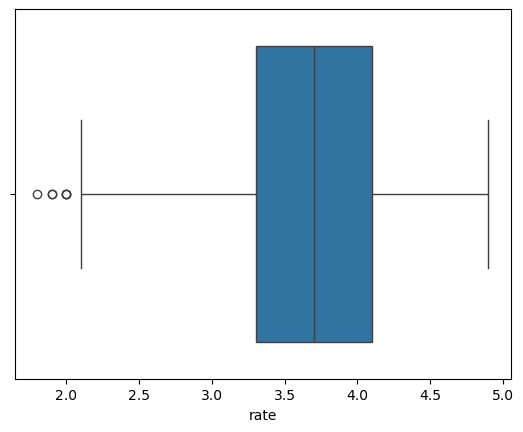

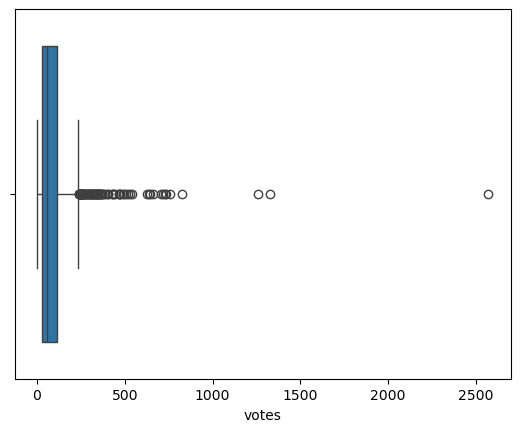

In [15]:
sns.boxplot(x=df['rate'])
plt.show()
sns.boxplot(x=df['votes'])
plt.show()


In [16]:
for col in ['location', 'cuisines']:
    print(col, (df[col] == 'Unknown').sum())

location 0
cuisines 0


In [20]:
df['rate'].mean()

3.717

In [21]:
df['rate'].max()

4.9

In [22]:
df['rate'].min()

1.8

In [23]:
df['rate'].value_counts().sort_index()

rate
1.8     1
1.9     2
2.0     3
2.1     4
2.2     1
2.3     6
2.4     4
2.5     8
2.6     8
2.7    19
2.8    20
2.9    24
3.0    34
3.1    35
3.2    41
3.3    65
3.4    48
3.5    48
3.6    64
3.7    93
3.8    70
3.9    69
4.0    42
4.1    57
4.2    45
4.3    37
4.4    28
4.5    32
4.6    14
4.7    26
4.8    17
4.9    35
Name: count, dtype: int64

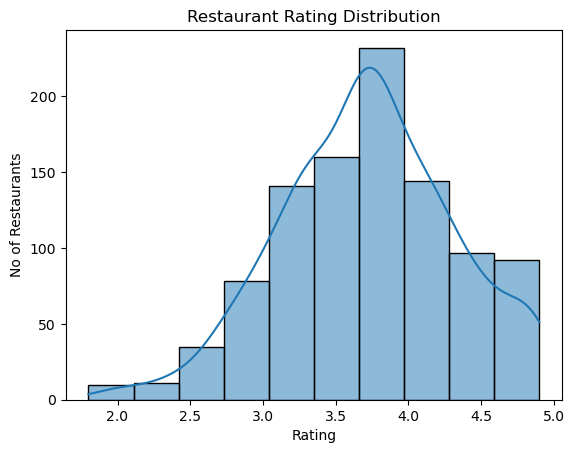

In [25]:
# rating histogram
plt.figure(figure=(8,5))
sns.histplot(df['rate'],bins=10, kde=True)
plt.title("Restaurant Rating Distribution")
plt.xlabel("Rating")
plt.ylabel("No of Restaurants")
plt.show()

cuisines
Andhra          60
Thai            40
Cafe            40
Desserts        38
Chinese         37
Continental     35
Mughlai         35
Italian         34
South Indian    32
Bakery          31
Name: count, dtype: int64


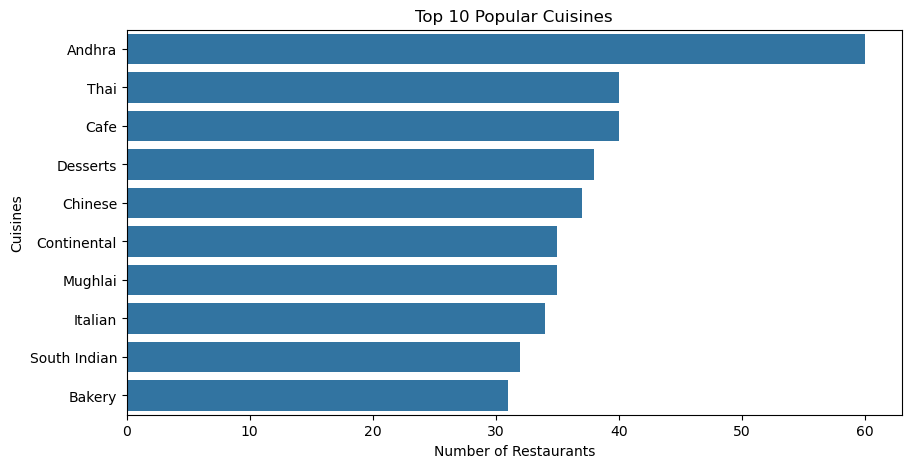

In [26]:
# Cuisine Popularity Analysis

cuisine_counts = df['cuisines'].value_counts().head(10)
print(cuisine_counts)

plt.figure(figsize=(10,5))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index)
plt.title("Top 10 Popular Cuisines")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisines")
plt.show()

In [28]:
city_count= df['location'].value_counts()
city_count

location
MG Road            104
Whitefield          90
Rajajinagar         90
Indiranagar         87
BTM Layout          86
Marathahalli        84
Electronic City     81
Koramangala         79
Malleshwaram        78
Jayanagar           78
HSR Layout          77
JP Nagar            66
Name: count, dtype: int64

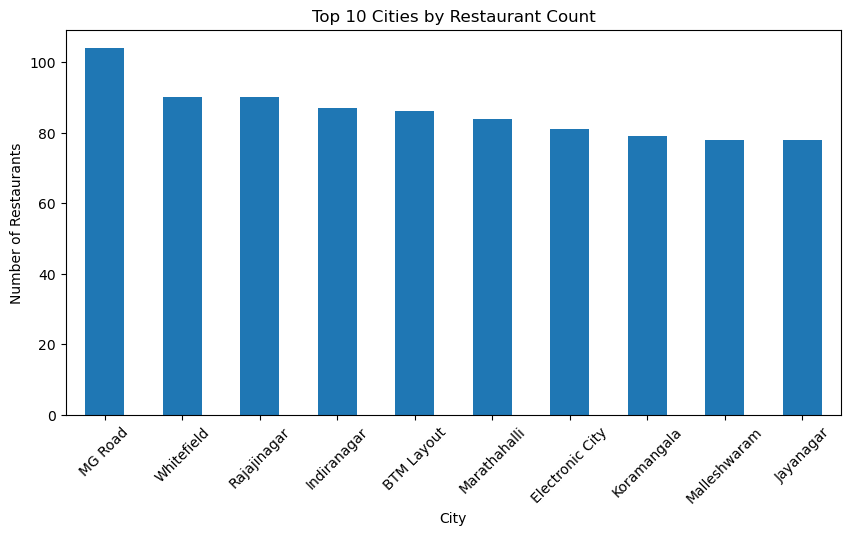

In [29]:
#city wise Restaurants
plt.figure(figsize=(10,5))
city_count.head(10).plot(kind='bar')
plt.title("Top 10 Cities by Restaurant Count")
plt.xlabel("City")
plt.ylabel("Number of Restaurants")
plt.xticks(rotation=45)
plt.show()

In [31]:
# Pricing Trends Analysis

cost_col = 'approx_cost(for two people)'
df[cost_col] = pd.to_numeric(
    df[cost_col].astype(str).str.replace(',', ''),
    errors='coerce')
df[cost_col].mean()
df[cost_col].min()
df[cost_col].max()

2000

online_order
Yes    508
No     492
Name: count, dtype: int64


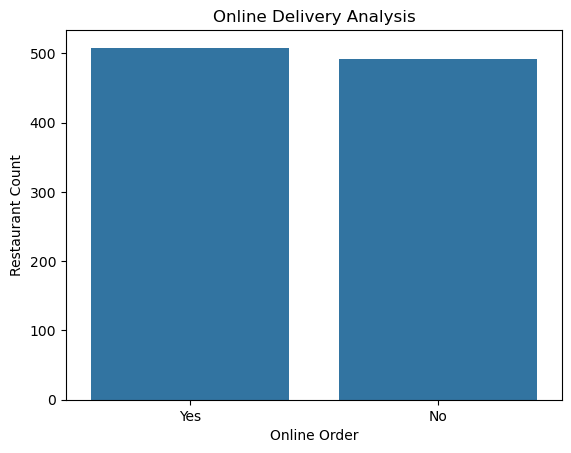

In [32]:
# Online Delivery Analysis

print(df['online_order'].value_counts())
sns.countplot(data=df, x='online_order')
plt.title("Online Delivery Analysis")
plt.xlabel("Online Order")
plt.ylabel("Restaurant Count")
plt.show()

In [33]:
#Business Insights
print("Total Restaurants:", len(df))
print("Total Cities:", df['location'].nunique())
print("Average Rating:", df['rate'].mean())
print("Most Popular Cuisine:")
print(df['cuisines'].value_counts().head(1))
print("Online Delivery Restaurants:")
print(df['online_order'].value_counts())

Total Restaurants: 1000
Total Cities: 12
Average Rating: 3.717
Most Popular Cuisine:
cuisines
Andhra    60
Name: count, dtype: int64
Online Delivery Restaurants:
online_order
Yes    508
No     492
Name: count, dtype: int64


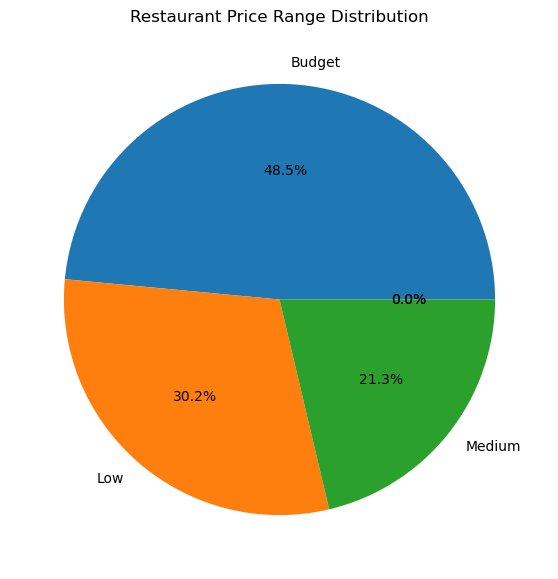

In [34]:
#Price Range Pie Chart
plt.figure(figsize=(7,7))
price_range = pd.cut(
    df[cost_col],
    bins=[0, 500, 1000, 2000, 5000, float('inf')],
    labels=['Budget', 'Low', 'Medium', 'High', 'Premium'])
price_range.value_counts().plot(
    kind='pie',
    autopct='%1.1f%%')

plt.title("Restaurant Price Range Distribution")
plt.ylabel("")
plt.show()

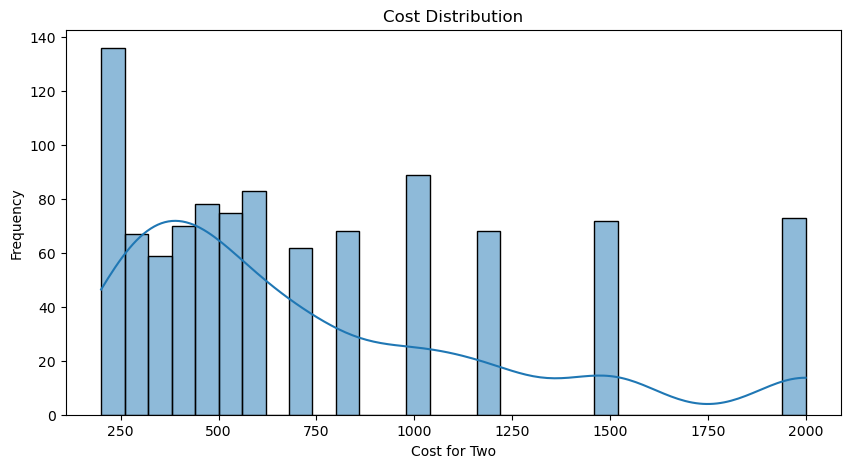

In [35]:
#Cost Distribution Histogram
plt.figure(figsize=(10,5))
sns.histplot(df[cost_col].dropna(), bins=30, kde=True)

plt.title("Cost Distribution")
plt.xlabel("Cost for Two")
plt.ylabel("Frequency")
plt.show()

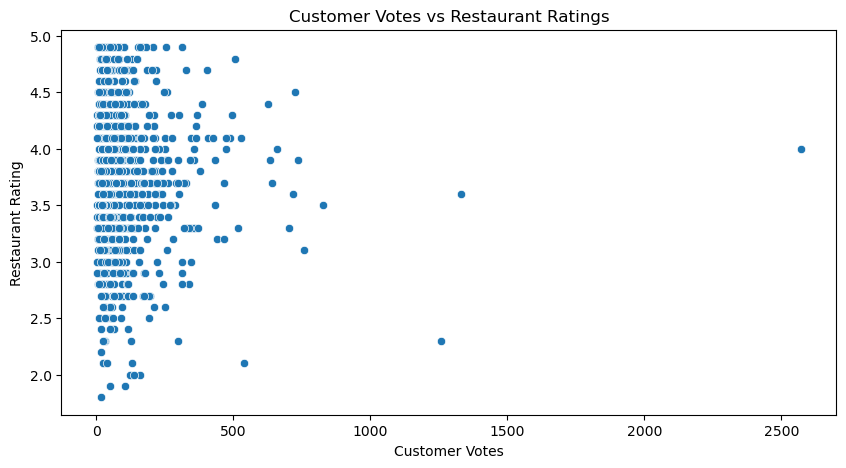

In [36]:
#Customer Votes Scatter Plot
plt.figure(figsize=(10,5))
sns.scatterplot(data=df, x='votes', y='rate')

plt.title("Customer Votes vs Restaurant Ratings")
plt.xlabel("Customer Votes")
plt.ylabel("Restaurant Rating")
plt.show()

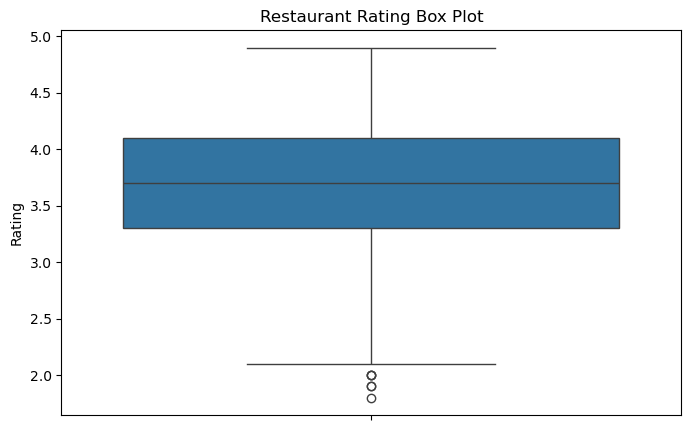

In [37]:
#Rating Box Plot
plt.figure(figsize=(8,5))
sns.boxplot(y='rate', data=df)

plt.title("Restaurant Rating Box Plot")
plt.ylabel("Rating")
plt.show()

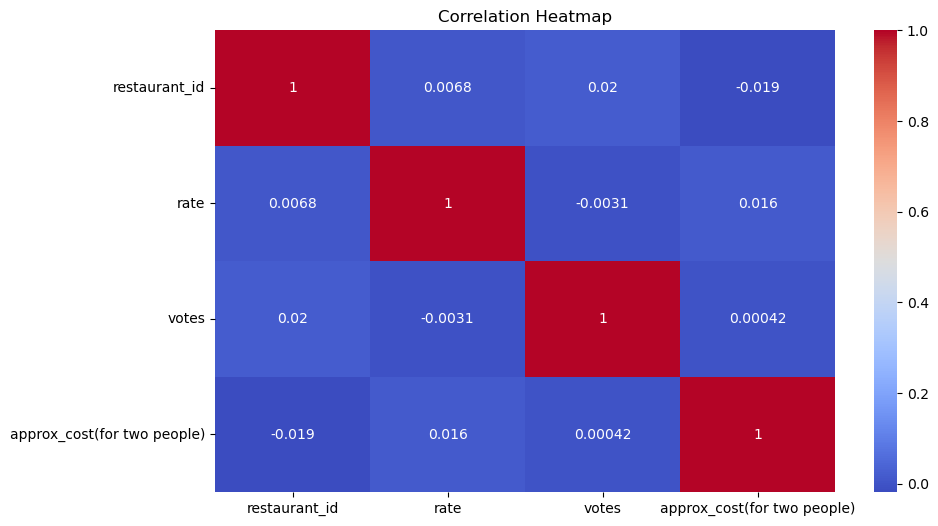

In [38]:
#Correlation Heatmap
plt.figure(figsize=(10,6))
sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm')

plt.title("Correlation Heatmap")
plt.show()

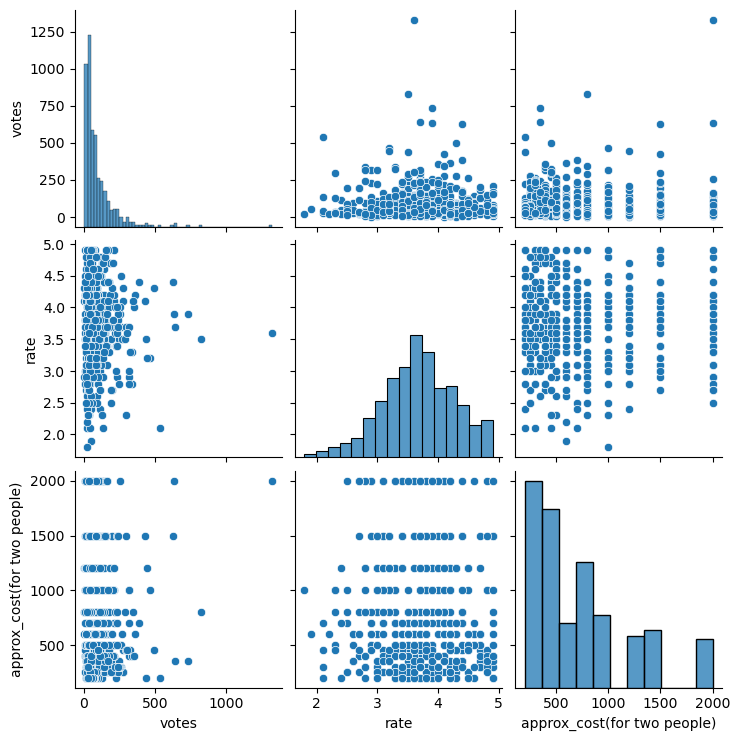

In [41]:
#Pair Plot
sns.pairplot(
    df[['votes', 'rate', cost_col]].dropna().sample(
        min(500, len(df.dropna())))
)

plt.show()

In [43]:
df['rate'] = pd.to_numeric(
    df['rate'].astype(str).str.replace('/5', '', regex=False),
    errors='coerce')

In [44]:
df.to_csv(
    "Zomato_Cleaned_Dataset.csv",
    index=False
)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [45]:
summary = f"""
ZOMATO RESTAURANT ANALYSIS

Total Restaurants: {len(df)}
Total Cities: {df['location'].nunique()}
Average Cost for Two: {df[cost_col].mean():.2f}

Top 5 Cuisines:
{df['cuisines'].value_counts().head(5)}

Online Order Analysis:
{df['online_order'].value_counts()}

This project analyzes restaurant ratings,
customer preferences, pricing and delivery.
"""

with open("Zomato_Executive_Summary.txt", "w") as f:
    f.write(summary)

print("Executive Summary Generated!")

Executive Summary Generated!


In [46]:
from matplotlib.backends.backend_pdf import PdfPages

In [47]:
with PdfPages("Zomato_Analysis_Report.pdf") as pdf:

    fig, ax = plt.subplots(figsize=(10,6))
    sns.histplot(df['rate'].dropna(), ax=ax)
    ax.set_title("Restaurant Rating Histogram")
    pdf.savefig(fig)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(10,6))
    df['cuisines'].value_counts().head(10).plot(
        kind='bar', ax=ax
    )
    ax.set_title("Top 10 Cuisines")
    pdf.savefig(fig)
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(10,6))
    sns.histplot(df[cost_col].dropna(), ax=ax)
    ax.set_title("Cost Distribution")
    pdf.savefig(fig)
    plt.close(fig)

print("PDF Report Generated Successfully!")

PDF Report Generated Successfully!
